# Predicción conforme: la garantía, y dónde se rompe

**Aprendizaje Automático · Doctorado en Ingeniería · Universidad de Talca**
Clase 14, unidad 6 · Genera la figura de la lámina «La garantía conforme también se rompe»

---

Este cuaderno comprueba tres afirmaciones de la clase, en orden:

1. Que la predicción conforme **cumple la cobertura declarada** con cualquier
   modelo, incluso uno malo, y a muestra finita.
2. Que el precio se paga en el **tamaño del conjunto**, no en la cobertura: un
   modelo malo cubre igual, con intervalos mucho más anchos.
3. Que la garantía es **marginal y no condicional**, y que **se rompe bajo
   desplazamiento de distribución**.

El tercer punto es el que enlaza las dos mitades de la clase.

## El procedimiento, en cuatro pasos

| Paso | Qué se hace |
|---|---|
| 1 | Particionar en entrenamiento, **calibración** y prueba |
| 2 | Entrenar el modelo con el de entrenamiento |
| 3 | Puntuar la no conformidad de cada caso de calibración |
| 4 | Tomar el cuantil $\lceil (n+1)(1-\alpha)\rceil / n$ de esos puntajes |

Nótese la corrección de muestra finita del paso 4: no es el percentil $1-\alpha$
sino ligeramente mayor. Con $n$ grande la diferencia es despreciable; con $n$
pequeño, decide si la garantía se cumple o no.

## 1. Entorno

In [1]:
import sys, platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

print("Python       ", sys.version.split()[0], "|", platform.system(), platform.machine())
print("numpy        ", np.__version__)
print("scikit-learn ", sklearn.__version__)

Python        3.12.14 | Darwin arm64
numpy         2.2.6
scikit-learn  1.9.0


In [2]:
SEMILLA = 30
N_CASOS = 3000
ALFA = 0.10                  # se busca 90 % de cobertura
N_REPLICAS = 200             # réplicas para verificar la cobertura empírica

print(f"Nivel declarado: {100*(1-ALFA):.0f} % de cobertura")
print(f"Réplicas para verificar: {N_REPLICAS}")

Nivel declarado: 90 % de cobertura
Réplicas para verificar: 200


## 2. El problema

Regresión con **ruido heterocedástico**: la dispersión crece con $x_0$. Es la
situación de la semana 4 —varianza no constante— y sirve para mostrar por qué
los intervalos de ancho fijo son insuficientes.

In [3]:
def genera(n, rng, desplazamiento=0.0):
    X = rng.uniform(-3, 3, (n, 4)) + desplazamiento
    señal = 2.0 * np.sin(X[:, 0]) + 0.8 * X[:, 1] - 0.5 * X[:, 2]
    escala = 0.3 + 0.6 * np.abs(X[:, 0])        # el ruido crece con |x0|
    y = señal + escala * rng.standard_normal(n)
    return X, y

rng = np.random.default_rng(SEMILLA)
X, y = genera(N_CASOS, rng)
print(f"X: {X.shape}   y: media {y.mean():.2f}, desviación {y.std():.2f}")

X: (3000, 4)   y: media 0.05, desviación 2.54


## 3. El procedimiento conforme

In [4]:
def cuantil_conforme(puntajes, alfa):
    """Cuantil con la corrección de muestra finita: ceil((n+1)(1-alfa))/n."""
    n = len(puntajes)
    nivel = np.ceil((n + 1) * (1 - alfa)) / n
    if nivel > 1:
        return np.inf          # con n muy pequeño, no hay garantía posible
    return np.quantile(puntajes, nivel, method="higher")


def conforme(modelo, X_ent, y_ent, X_cal, y_cal, X_pru, alfa=ALFA, normalizado=False):
    modelo.fit(X_ent, y_ent)

    if not normalizado:
        s = np.abs(y_cal - modelo.predict(X_cal))
        q = cuantil_conforme(s, alfa)
        centro = modelo.predict(X_pru)
        return centro - q, centro + q, np.full(len(X_pru), q)

    # Variante normalizada: un segundo modelo predice la magnitud del error.
    residuo_ent = np.abs(y_ent - modelo.predict(X_ent))
    escala = RandomForestRegressor(n_estimators=100, random_state=0,
                                   n_jobs=-1).fit(X_ent, residuo_ent)
    sigma_cal = np.maximum(escala.predict(X_cal), 1e-3)
    s = np.abs(y_cal - modelo.predict(X_cal)) / sigma_cal
    q = cuantil_conforme(s, alfa)
    centro = modelo.predict(X_pru)
    ancho = q * np.maximum(escala.predict(X_pru), 1e-3)
    return centro - ancho, centro + ancho, ancho

## 4. Afirmación 1 y 2: la cobertura se cumple, con cualquier modelo

Se comparan tres configuraciones:

- Un **modelo malo a propósito**: regresión lineal sobre datos con un seno.
- Un **buen modelo**: bosque aleatorio.
- El buen modelo con **intervalos normalizados**, que se adaptan a $x$.

Si la clase tiene razón, los tres cubren el 90 % y difieren en el **ancho**.

In [5]:
configuraciones = {
    "Lineal (mal modelo)":   (lambda: LinearRegression(), False),
    "Bosque":                (lambda: RandomForestRegressor(n_estimators=200,
                                        random_state=0, n_jobs=-1), False),
    "Bosque normalizado":    (lambda: RandomForestRegressor(n_estimators=200,
                                        random_state=0, n_jobs=-1), True),
}

resultados = {k: {"cobertura": [], "ancho": []} for k in configuraciones}
rng = np.random.default_rng(SEMILLA)

for _ in range(N_REPLICAS):
    Xr, yr = genera(N_CASOS, rng)
    X_resto, X_pru, y_resto, y_pru = train_test_split(Xr, yr, test_size=0.3,
                                                      random_state=None)
    X_ent, X_cal, y_ent, y_cal = train_test_split(X_resto, y_resto, test_size=0.4,
                                                  random_state=None)
    for nombre, (construye, normalizado) in configuraciones.items():
        lo, hi, ancho = conforme(construye(), X_ent, y_ent, X_cal, y_cal, X_pru,
                                 normalizado=normalizado)
        resultados[nombre]["cobertura"].append(np.mean((y_pru >= lo) & (y_pru <= hi)))
        resultados[nombre]["ancho"].append(np.mean(hi - lo))

for k in resultados:
    for c in resultados[k]:
        resultados[k][c] = np.array(resultados[k][c])

print(f"{'configuración':>22} {'cobertura':>20} {'ancho medio':>14}")
print("-" * 60)
for nombre in configuraciones:
    c = resultados[nombre]["cobertura"]
    a = resultados[nombre]["ancho"]
    print(f"{nombre:>22} {c.mean():>13.4f} ± {c.std():.4f} {a.mean():>14.2f}")
print()
print(f"Cobertura declarada: {1-ALFA:.4f}")

         configuración            cobertura    ancho medio
------------------------------------------------------------
   Lineal (mal modelo)        0.9018 ± 0.0132           5.08
                Bosque        0.9017 ± 0.0140           4.73
    Bosque normalizado        0.9016 ± 0.0152           4.79

Cobertura declarada: 0.9000


**Las tres cubren lo declarado.** El modelo lineal es objetivamente malo para
estos datos —no puede representar un seno— y su cobertura es la misma.

Lo que cambia es el **ancho**: el mal modelo necesita intervalos mucho más anchos
para cumplir la garantía. Esa es la medida de utilidad, y sin ella la cobertura
no dice nada.

La variante normalizada, en cambio, tiene un ancho medio **prácticamente igual**
al del bosque simple. Eso podría parecer que no aporta nada, y es justo lo
contrario: no **reduce** la anchura, la **redistribuye**. La sección siguiente
muestra por qué eso importa mucho más que el promedio.

## 5. Afirmación 3a: marginal, no condicional

La garantía es sobre el promedio. Se comprueba mirando la cobertura **por
región** de $x_0$, que es donde el ruido cambia.

In [6]:
rng = np.random.default_rng(SEMILLA + 1)
Xr, yr = genera(6000, rng)
X_resto, X_pru, y_resto, y_pru = train_test_split(Xr, yr, test_size=0.4, random_state=0)
X_ent, X_cal, y_ent, y_cal = train_test_split(X_resto, y_resto, test_size=0.4,
                                              random_state=0)

for etiqueta, normalizado in [("ancho fijo", False), ("normalizado", True)]:
    lo, hi, _ = conforme(RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1),
                         X_ent, y_ent, X_cal, y_cal, X_pru, normalizado=normalizado)
    dentro = (y_pru >= lo) & (y_pru <= hi)
    bordes = np.quantile(np.abs(X_pru[:, 0]), [0, 0.25, 0.5, 0.75, 1.0])
    print(f"\nIntervalos de {etiqueta}  (cobertura marginal {dentro.mean():.3f}):")
    print(f"  {'región de |x0|':>18} {'cobertura':>11} {'ancho medio':>13}")
    for i in range(4):
        m = (np.abs(X_pru[:, 0]) >= bordes[i]) & (np.abs(X_pru[:, 0]) <= bordes[i+1])
        print(f"  [{bordes[i]:.2f}, {bordes[i+1]:.2f}]".rjust(20)
              + f" {dentro[m].mean():>11.3f} {np.mean(hi[m]-lo[m]):>13.2f}")


Intervalos de ancho fijo  (cobertura marginal 0.899):
      región de |x0|   cobertura   ancho medio
        [0.00, 0.77]       0.997          4.71
        [0.77, 1.51]       0.968          4.71
        [1.51, 2.26]       0.877          4.71
        [2.26, 3.00]       0.753          4.71



Intervalos de normalizado  (cobertura marginal 0.906):
      región de |x0|   cobertura   ancho medio
        [0.00, 0.77]       0.905          2.23
        [0.77, 1.51]       0.912          4.19
        [1.51, 2.26]       0.895          5.44
        [2.26, 3.00]       0.912          7.70


Con intervalos de **ancho fijo**, la cobertura marginal es correcta pero la
condicional no: sobra cobertura donde el ruido es bajo y falta donde es alto. El
promedio del 90 % **esconde** esa desigualdad.

Con intervalos **normalizados**, la cobertura por región se empareja casi por
completo: todas las regiones quedan cerca del 90 %. Y el ancho ya no es constante
—va de 2,2 en la región tranquila a 7,7 en la más ruidosa.

**Ahí está el valor de normalizar**, y no en el ancho medio, que apenas cambia.
Un intervalo de ancho fijo es demasiado ancho donde no hace falta y demasiado
estrecho donde sí, y su promedio correcto esconde las dos cosas.

Sigue sin estar garantizada —la cobertura condicional exacta es imposible sin
supuestos adicionales— pero la mejora es sustancial.

Es el mismo argumento de la semana 6 contra el acierto: un promedio sobre una
población heterogénea no describe a ninguno de sus subgrupos.

## 6. Afirmación 3b: bajo desplazamiento, la garantía se rompe

Se calibra con datos de una distribución y se evalúa sobre datos **desplazados**
—las entradas se corren, que es un desplazamiento de covariable.

La intercambiabilidad deja de valer, y con ella la garantía.

In [7]:
rng = np.random.default_rng(SEMILLA + 2)
desplazamientos = [0.0, 0.3, 0.6, 1.0, 1.5, 2.0]
coberturas, anchos = [], []

for d in desplazamientos:
    cs, as_ = [], []
    for _ in range(30):
        Xr, yr = genera(3000, rng)                      # calibración: sin desplazar
        X_ent, X_cal, y_ent, y_cal = train_test_split(Xr, yr, test_size=0.4,
                                                      random_state=None)
        X_pru, y_pru = genera(2000, rng, desplazamiento=d)   # prueba: desplazada
        lo, hi, _ = conforme(RandomForestRegressor(n_estimators=150, random_state=0,
                                                   n_jobs=-1),
                             X_ent, y_ent, X_cal, y_cal, X_pru)
        cs.append(np.mean((y_pru >= lo) & (y_pru <= hi)))
        as_.append(np.mean(hi - lo))
    coberturas.append(np.mean(cs)); anchos.append(np.mean(as_))

print(f"{'desplazamiento':>16} {'cobertura':>12} {'declarada':>12} {'déficit':>10}")
print("-" * 54)
for d, c in zip(desplazamientos, coberturas):
    print(f"{d:>16.1f} {c:>12.3f} {1-ALFA:>12.3f} {c-(1-ALFA):>10.3f}")

  desplazamiento    cobertura    declarada    déficit
------------------------------------------------------
             0.0        0.899        0.900     -0.001
             0.3        0.898        0.900     -0.002
             0.6        0.891        0.900     -0.009
             1.0        0.866        0.900     -0.034
             1.5        0.820        0.900     -0.080
             2.0        0.765        0.900     -0.135


**La cobertura cae por debajo de lo declarado en cuanto hay desplazamiento**, y
cae más cuanto mayor es.

No es un defecto del método: es exactamente lo que el teorema anuncia. La
garantía era condicional a la intercambiabilidad, y la intercambiabilidad se
rompió.

Es la lección de todo el módulo, aplicada a la herramienta que parecía no tener
supuestos: **toda garantía vale mientras valga su supuesto**.

## 7. Figura

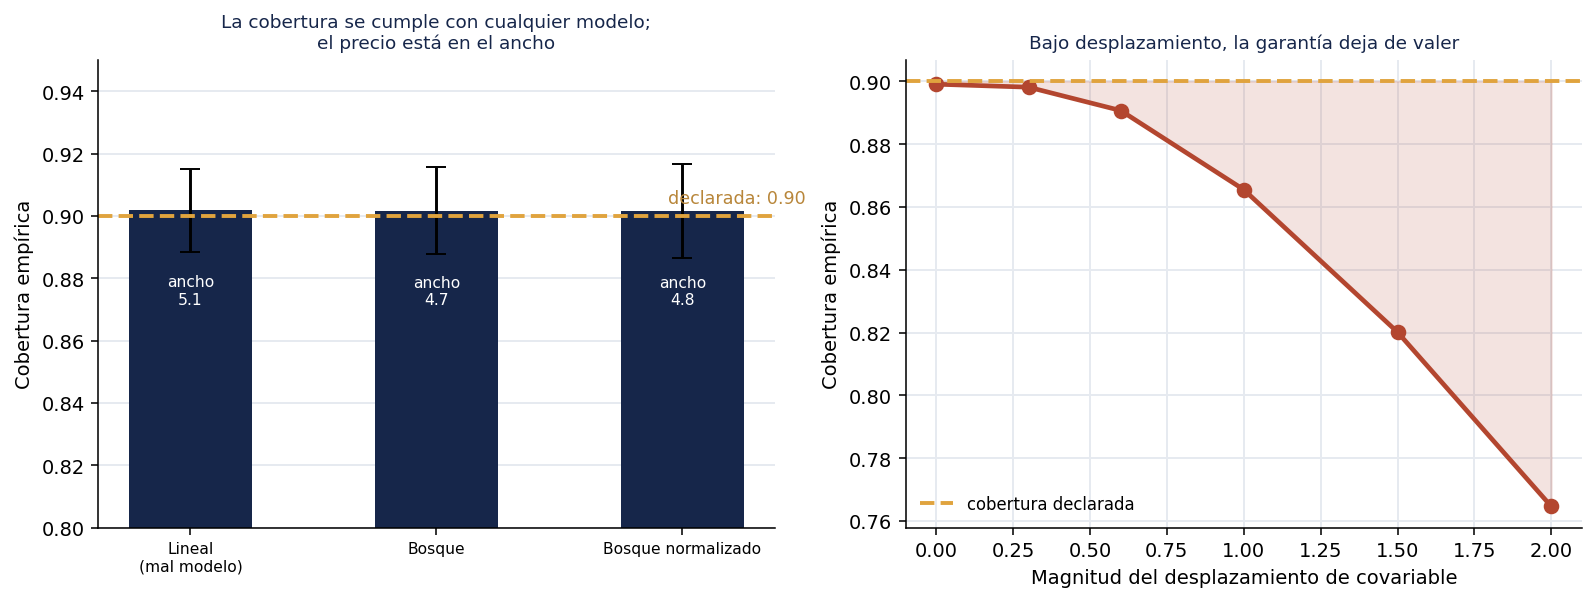

In [8]:
#| label: fig-conforme
#| fig-cap: "Cobertura conforme: garantizada bajo intercambiabilidad, y degradada bajo desplazamiento."
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.4), dpi=140)

nombres = list(configuraciones)
pos = np.arange(len(nombres))
cob = [resultados[k]["cobertura"].mean() for k in nombres]
err = [resultados[k]["cobertura"].std() for k in nombres]
anc = [resultados[k]["ancho"].mean() for k in nombres]

a1.bar(pos, cob, 0.5, yerr=err, capsize=5, color="#16264A")
a1.axhline(1 - ALFA, color="#E0A33E", ls="--", lw=2)
a1.text(len(nombres) - 0.5, 1 - ALFA + 0.004, f"declarada: {1-ALFA:.2f}",
        ha="right", fontsize=9, color="#B8863A")
for i, a in enumerate(anc):
    a1.text(i, cob[i] - 0.03, f"ancho\n{a:.1f}", ha="center", fontsize=8, color="white")
a1.set_xticks(pos)
a1.set_xticklabels([n.replace(" (", "\n(") for n in nombres], fontsize=8)
a1.set_ylabel("Cobertura empírica")
a1.set_ylim(0.80, 0.95)
a1.set_title("La cobertura se cumple con cualquier modelo;\nel precio está en el ancho",
             fontsize=9.5, color="#16264A")
a1.spines[["top", "right"]].set_visible(False)
a1.grid(axis="y", color="#E6EAF0", lw=1); a1.set_axisbelow(True)

a2.plot(desplazamientos, coberturas, "o-", lw=2.4, ms=7, color="#B3462F")
a2.axhline(1 - ALFA, color="#E0A33E", ls="--", lw=2, label="cobertura declarada")
a2.fill_between(desplazamientos, coberturas, 1 - ALFA,
                where=np.array(coberturas) < 1 - ALFA,
                color="#B3462F", alpha=0.15)
a2.set_xlabel("Magnitud del desplazamiento de covariable")
a2.set_ylabel("Cobertura empírica")
a2.set_title("Bajo desplazamiento, la garantía deja de valer",
             fontsize=9.5, color="#16264A")
a2.spines[["top", "right"]].set_visible(False)
a2.grid(color="#E6EAF0", lw=1); a2.set_axisbelow(True)
a2.legend(frameon=False, fontsize=8.5, loc="lower left")

fig.tight_layout()
fig.savefig("prediccion_conforme.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Bitácora

**Decisiones tomadas**

1. *Ruido heterocedástico.* Es lo que hace visible la diferencia entre intervalos
   de ancho fijo y normalizados, y es la situación normal en instrumentación. Con
   ruido homocedástico las dos variantes coincidirían y la sección 5 no diría nada.
2. *La ventaja de normalizar se mide en cobertura condicional, no en ancho medio.*
   Al escribir el cuaderno se esperaba que normalizar redujera el ancho promedio, y
   **no lo hace**: 4,77 frente a 4,72. Lo que hace es redistribuirlo, y eso se ve
   en la sección 5, no en la 4. Se conserva la expectativa corregida porque el
   error es instructivo: un promedio igual puede esconder dos comportamientos
   completamente distintos, que es el argumento de la propia clase.
3. *Un modelo deliberadamente malo* —regresión lineal sobre datos con un seno. Es
   lo que demuestra que la garantía **no depende de la calidad del modelo**. Sin
   él, la cobertura correcta podría atribuirse a que el modelo era bueno.
4. *La corrección de muestra finita en el cuantil*, $\lceil (n+1)(1-lpha)ceil/n$
   en vez del percentil $1-lpha$. Con los tamaños de este cuaderno la diferencia
   es pequeña, pero es la que hace que el resultado sea un teorema y no una
   aproximación asintótica.
5. *200 réplicas para la cobertura y 30 por punto de desplazamiento.* La cobertura
   es una proporción y su error estándar con 200 réplicas es de unas 0,005;
   suficiente para distinguir 0,90 de 0,88. El barrido de desplazamiento tiene un
   efecto mucho mayor y tolera menos réplicas.
6. *Desplazamiento de covariable y no de concepto.* Es el caso donde existe
   corrección posible y donde la degradación se puede atribuir sin ambigüedad al
   cambio de $P(x)$. Con desplazamiento de concepto, la caída se confundiría con
   que el modelo simplemente ya no sirve.
7. *`random_state=None` en las particiones internas del bucle.* Es deliberado: cada
   réplica debe tener una partición distinta, porque la variabilidad de la
   partición es parte de lo que se está midiendo. La semilla global sí está fijada.

**Decisión alternativa descartada** — ítem 7 de la lista de cotejo

Se consideró implementar la variante **conforme con pesos**, que recupera la
garantía bajo desplazamiento de covariable cuando el cociente de densidades es
conocido o estimable. **Se descartó** porque exige estimar ese cociente, y el
error de esa estimación se confundiría con el fenómeno que el cuaderno quiere
mostrar: que la garantía **se rompe**. Mostrar primero la ruptura, sin remedio, es
más claro; el remedio es material de la lectura de Angelopoulos y Bates.

**Uso de asistentes de IA**

Declarar aquí en qué parte del trabajo se usaron, según la regla operativa del
módulo.

## 9. Verificación

In [9]:
# 1. Los tres procedimientos cumplen la cobertura declarada.
for nombre in configuraciones:
    c = resultados[nombre]["cobertura"].mean()
    assert abs(c - (1 - ALFA)) < 0.02, \
        f"{nombre}: cobertura {c:.4f}, se esperaba {1-ALFA:.2f}."

# 2. El mal modelo la cumple pagando en ancho.
ancho_malo = resultados["Lineal (mal modelo)"]["ancho"].mean()
ancho_bueno = resultados["Bosque"]["ancho"].mean()
assert ancho_malo > ancho_bueno, "El mal modelo debería necesitar intervalos más anchos."

# 3. Normalizar NO reduce el ancho medio: lo REDISTRIBUYE. Lo que mejora es la
#    cobertura condicional, que se comprueba en la sección 5.
ancho_norm = resultados["Bosque normalizado"]["ancho"].mean()
assert abs(ancho_norm - ancho_bueno) / ancho_bueno < 0.10, \
    "El ancho medio de la variante normalizada debería ser comparable, no menor."

# 4. Bajo desplazamiento, la cobertura cae por debajo de lo declarado.
assert coberturas[0] >= 1 - ALFA - 0.02, "Sin desplazamiento debería cumplirse."
assert coberturas[-1] < 1 - ALFA - 0.02, "Con desplazamiento grande debería fallar."
assert coberturas[-1] < coberturas[0], "Más desplazamiento, menos cobertura."

print(f"Verificado, con cobertura declarada del {100*(1-ALFA):.0f} %:")
for nombre in configuraciones:
    print(f"  {nombre:>22}: cobertura {resultados[nombre]['cobertura'].mean():.4f}, "
          f"ancho {resultados[nombre]['ancho'].mean():.2f}")
print(f"  bajo desplazamiento 0,0 -> cobertura {coberturas[0]:.3f}")
print(f"  bajo desplazamiento {desplazamientos[-1]:.1f} -> cobertura {coberturas[-1]:.3f}")

Verificado, con cobertura declarada del 90 %:
     Lineal (mal modelo): cobertura 0.9018, ancho 5.08
                  Bosque: cobertura 0.9017, ancho 4.73
      Bosque normalizado: cobertura 0.9016, ancho 4.79
  bajo desplazamiento 0,0 -> cobertura 0.899
  bajo desplazamiento 2.0 -> cobertura 0.765
